# TP3 · Asistente interno para la capacitación administrativa de un aserradero


Este chatbot está orientado a personas que se incorporan al área administrativa
de un aserradero. Su objetivo es ayudar a consultar y recordar los procedimientos
de recepción de madera, selección del peso que se registra, carga de datos y
controles del cierre quincenal. Funciona como apoyo a la capacitación: responde
consultas sobre los procedimientos incluidos en su base, pero no carga operaciones
ni realiza liquidaciones.

Se comparan dos chatbots de recuperación: uno con **TF-IDF** y otro con los
**vectores preentrenados en español de spaCy**. Ambos buscan una pregunta del
corpus mediante similitud coseno y devuelven su respuesta guardada.

El caso educativo describe un procedimiento particular de recepción y registro
de madera. No pretende fijar reglas universales, validar procedimientos de
seguridad ni brindar asesoramiento legal. No incluye nombres reales de empresas,
clientes, personas ni precios.

**Contenido:** implementación de ambos métodos, pruebas, análisis de errores y reflexión. Se conservan las salidas de la ejecución. Antes de entregar, falta incorporar la referencia real de asistencia de IA y el enlace al video, y verificar que los enlaces de entrega sean accesibles.

Para usarlo en Colab: abrir el archivo y ejecutar las celdas en orden. Los datos
están incluidos en el notebook; no requiere subir los JSON por separado. La
primera ejecución necesita Internet para instalar el modelo oficial si falta.

## 1. Preparación

Se utiliza scikit-learn para TF-IDF y coseno. Para embeddings se utiliza
`es_core_news_md` 3.8.0, el modelo en español presentado en el ejemplo de clase.
Contiene vectores de palabras preentrenados; no se entrenan embeddings con este
corpus pequeño. Su dominio de origen es texto periodístico, por lo que puede
representar mal vocabulario específico del aserradero.

La instalación se hace desde PyPI y el repositorio oficial de modelos de spaCy.
No se reemplaza el modelo por vectores aleatorios si falla la descarga: en ese
caso hay que resolver el error antes de comparar los dos métodos.

In [ ]:
import importlib.util
import subprocess
import sys
from importlib.metadata import version, PackageNotFoundError

dependencias = {"numpy": "numpy", "pandas": "pandas",
                "sklearn": "scikit-learn", "spacy": "spacy==3.8.7"}
faltantes = [paquete for modulo, paquete in dependencias.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])

if version("spacy") != "3.8.7":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "spacy==3.8.7"])

try:
    version_modelo = version("es_core_news_md")
except PackageNotFoundError:
    version_modelo = None
if version_modelo != "3.8.0":
    modelo_url = ("https://github.com/explosion/spacy-models/releases/download/"
                  "es_core_news_md-3.8.0/es_core_news_md-3.8.0-py3-none-any.whl")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", modelo_url])

import json
import re
import hashlib
import platform
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import spacy
if spacy.__version__ != "3.8.7":
    raise RuntimeError("Reiniciar la sesión de Colab para cargar la versión instalada de spaCy y ejecutar todo otra vez.")
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

print("Python:", platform.python_version())
for paquete in ["numpy", "pandas", "scikit-learn", "spacy", "es_core_news_md"]:
    print(paquete, version(paquete))

Python: 3.13.16
numpy 2.1.3
pandas 2.2.3
scikit-learn 1.6.1
spacy 3.8.7
es_core_news_md 3.8.0


## 2. Corpus y alcance

Cada ID identifica una respuesta. La fuente del caso son los datos aportados y
confirmados por el estudiante; la redacción se organizó con asistencia de IA.
Se distinguen madera propia/comprada, peso bruto/neto/tara y kilos/toneladas.
Las preguntas representan dudas de una persona nueva en administración y las
respuestas indican qué hacer. La conversión de kilos a toneladas es aritmética:
se divide por 1.000. El lote puede faltar sin impedir el registro. La pauta para
datos necesarios faltantes indica consultar al proveedor y esperar antes de cargar.

Los JSON externos sirven para revisar y reutilizar los mismos datos. La copia
incluida a continuación permite ejecutar el notebook por sí solo.

In [ ]:
corpus = json.loads(r'''
[
  {
    "id": "P01",
    "pregunta": "Llegó un camión con madera. ¿Qué datos del remito tengo que cargar?",
    "respuesta": "Cargá el número de remito, el monte de origen y si la madera es propia o comprada."
  },
  {
    "id": "P02",
    "pregunta": "Llegó un camión con madera propia. ¿Qué peso cargo como final?",
    "respuesta": "Usá como peso final el obtenido con la balanza del aserradero."
  },
  {
    "id": "P03",
    "pregunta": "Llegó un camión con madera comprada. ¿Qué peso cargo como final?",
    "respuesta": "Usá como peso final el informado por el proveedor."
  },
  {
    "id": "P04",
    "pregunta": "¿Cómo calculo el peso neto de la madera propia?",
    "respuesta": "Restá la tara al peso bruto: peso neto = peso bruto - tara."
  },
  {
    "id": "P05",
    "pregunta": "¿Peso el chasis y el acoplado juntos o por separado?",
    "respuesta": "Pesalos por separado, porque la balanza es demasiado corta para pesar el conjunto completo."
  },
  {
    "id": "P06",
    "pregunta": "¿Qué tara uso y cada cuánto se actualiza?",
    "respuesta": "Usá la tara fija registrada. Se actualiza cada tres meses."
  },
  {
    "id": "P07",
    "pregunta": "¿Tengo que volver a pesar el camión cuando queda vacío?",
    "respuesta": "Con el procedimiento actual, no se vuelve a pesar el camión vacío porque con la infraestructura disponible no resulta práctico."
  },
  {
    "id": "P08",
    "pregunta": "¿Qué datos del viaje y del transporte tengo que cargar?",
    "respuesta": "Cargá la fecha, el chofer, la empresa de transporte y la patente."
  },
  {
    "id": "P09",
    "pregunta": "Además del monte de origen, ¿qué otro dato registro de la procedencia?",
    "respuesta": "Registrá el lote, si está disponible."
  },
  {
    "id": "P10",
    "pregunta": "¿Qué características de la madera tengo que cargar?",
    "respuesta": "Cargá la calidad y la longitud de la madera."
  },
  {
    "id": "P11",
    "pregunta": "¿Cuándo corresponde la categoría más 22?",
    "respuesta": "Cuando el diámetro es mayor que 22 centímetros. Si mide exactamente 22 centímetros, no entra en esa categoría."
  },
  {
    "id": "P12",
    "pregunta": "¿Cargo siempre 4,1 metros como largo de la madera?",
    "respuesta": "No. El largo habitual es de 4,1 metros, pero no toda la madera tiene esa medida."
  },
  {
    "id": "P13",
    "pregunta": "Me falta un dato necesario para cargar el ingreso. ¿Qué hago?",
    "respuesta": "Consultá al proveedor y esperá la información necesaria antes de cargar el ingreso en el sistema."
  },
  {
    "id": "P14",
    "pregunta": "Falta el lote en el remito. ¿Puedo cargar el ingreso?",
    "respuesta": "Sí, podés cargarlo. El lote no es indispensable para registrar el ingreso."
  },
  {
    "id": "P15",
    "pregunta": "¿Cómo paso de kilos a toneladas?",
    "respuesta": "Dividí los kilos por 1.000. Por ejemplo, 2.500 kilos son 2,5 toneladas."
  },
  {
    "id": "P16",
    "pregunta": "¿Cargo los pesos en kilos o en toneladas?",
    "respuesta": "Cargá los pesos en kilogramos."
  },
  {
    "id": "P17",
    "pregunta": "¿En qué unidad preparo el detalle de liquidación y por qué?",
    "respuesta": "Preparalo en toneladas, porque a transportistas, contratistas y proveedores se les liquida por toneladas."
  },
  {
    "id": "P18",
    "pregunta": "Cargué un ingreso con un error. ¿Cómo lo corrijo?",
    "respuesta": "Editá el registro o volvé a hacer la carga."
  },
  {
    "id": "P19",
    "pregunta": "¿Cuándo se hacen normalmente los ajustes de las cargas?",
    "respuesta": "Normalmente se hacen al cierre de la quincena."
  },
  {
    "id": "P20",
    "pregunta": "¿Qué reviso al cerrar la quincena antes de liquidar?",
    "respuesta": "Compará las toneladas registradas con las reportadas por los proveedores para comprobar que coincidan y detectar diferencias."
  }
]
''')

In [ ]:
# Se revisaron los 20 pares de esta versión. La reflexión se incluye en la sección 11.
VERSION_CORPUS = "v2_capacitacion_interna"
CORPUS_REVISADO = True
MODO_ENTREGA = True

def validar_corpus(corpus, modo_entrega=False):
    assert len(corpus) >= 2, "Se necesitan al menos dos preguntas para comparar."
    ids = [fila["id"] for fila in corpus]
    assert len(ids) == len(set(ids)), "Hay IDs repetidos."
    preguntas = [fila["pregunta"].strip().lower() for fila in corpus]
    assert len(preguntas) == len(set(preguntas)), "Hay preguntas repetidas."
    for fila in corpus:
        assert isinstance(fila["pregunta"], str) and fila["pregunta"].strip()
        assert isinstance(fila["respuesta"], str) and fila["respuesta"].strip()
    if modo_entrega:
        assert len(corpus) >= 20, "La consigna exige al menos 20 pares."
        assert CORPUS_REVISADO, "Falta revisar y aprobar el corpus."
    return True

validar_corpus(corpus, MODO_ENTREGA)
print(f"Pares válidos: {len(corpus)}. Mínimo de 20: {len(corpus) >= 20}.")
print("Versión:", VERSION_CORPUS, "| Corpus revisado:", CORPUS_REVISADO)
display(pd.DataFrame(corpus))

Pares válidos: 20. Mínimo de 20: True.
Versión: v2_capacitacion_interna | Corpus revisado: True


,id,pregunta,respuesta
0,P01,Llegó un camión con madera. ¿Qué datos del rem...,"Cargá el número de remito, el monte de origen ..."
1,P02,Llegó un camión con madera propia. ¿Qué peso c...,Usá como peso final el obtenido con la balanza...
2,P03,Llegó un camión con madera comprada. ¿Qué peso...,Usá como peso final el informado por el provee...
3,P04,¿Cómo calculo el peso neto de la madera propia?,Restá la tara al peso bruto: peso neto = peso ...
4,P05,¿Peso el chasis y el acoplado juntos o por sep...,"Pesalos por separado, porque la balanza es dem..."
5,P06,¿Qué tara uso y cada cuánto se actualiza?,Usá la tara fija registrada. Se actualiza cada...
6,P07,¿Tengo que volver a pesar el camión cuando que...,"Con el procedimiento actual, no se vuelve a pe..."
7,P08,¿Qué datos del viaje y del transporte tengo qu...,"Cargá la fecha, el chofer, la empresa de trans..."
8,P09,"Además del monte de origen, ¿qué otro dato reg...","Registrá el lote, si está disponible."
9,P10,¿Qué características de la madera tengo que ca...,Cargá la calidad y la longitud de la madera.


## 3. Pruebas de la versión 2 fijadas antes de ejecutarla

Se usan exactamente las mismas consultas y respuestas esperadas para ambos
métodos. Se fija el ID esperado antes de evaluarlos. `None` significa que se
espera una abstención, porque la consulta está vacía, es ambigua o no tiene
respuesta en el corpus.

- **Calibración:** sirve para seleccionar el umbral de cada método
- **Prueba reservada de esta versión:** se usa después de fijar los umbrales y no
  participa en esa elección

Las preguntas son paráfrasis preparadas para este ejercicio con asistencia de IA,
no consultas recogidas de usuarios reales.
Se redactaron para la versión 2 después de haber revisado la versión 1. Algunas
comprobaciones de entrada vacía y palabras inventadas se conservan. Por eso no se
presentan como un conjunto externo totalmente ciego ni como consultas nunca vistas
en todo el desarrollo. Se congelaron sus textos e IDs antes de calibrar esta
versión y no se retocaron los modelos mirando sus resultados.

El corpus y las consultas cambiaron respecto de la versión 1: sus porcentajes no
permiten medir directamente una mejora entre versiones. La comparación válida
aquí es entre los dos métodos sobre el mismo conjunto de la versión 2.
Los conjuntos son pequeños y comparten las intenciones del corpus. Esto evalúa
recuperación de respuestas conocidas, no aprendizaje de nuevos procedimientos.
Si se modifica el sistema mirando fallos de la prueba, esa prueba pasa a ser de
desarrollo y habrá que preparar otra prueba independiente para una evaluación final.

In [ ]:
calibracion = json.loads(r'''
[
  {
    "id_prueba": "C2-01",
    "consulta": "¿Qué tengo que guardar del remito de un camión que llega?",
    "esperado": "P01",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-02",
    "consulta": "Para la madera propia, ¿qué pesada cargo como definitiva?",
    "esperado": "P02",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-03",
    "consulta": "¿Qué peso registro si la madera se compró a un proveedor?",
    "esperado": "P03",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-04",
    "consulta": "Tengo el bruto y la tara de madera propia. ¿Cómo saco el neto?",
    "esperado": "P04",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-05",
    "consulta": "¿El chasis y el acoplado se pesan separados?",
    "esperado": "P05",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-06",
    "consulta": "¿Qué valor de tara uso y cuándo se actualiza?",
    "esperado": "P06",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-07",
    "consulta": "Después de descargar, ¿hay que pesar otra vez el camión vacío?",
    "esperado": "P07",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-08",
    "consulta": "¿Qué información cargo sobre el viaje y el transportista?",
    "esperado": "P08",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-09",
    "consulta": "Ya anoté el monte de origen. ¿Qué dato más identifica la procedencia?",
    "esperado": "P09",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-10",
    "consulta": "¿Qué datos cargo sobre las características de la madera?",
    "esperado": "P10",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-11",
    "consulta": "¿Qué diámetro debe tener la madera para ser más 22?",
    "esperado": "P11",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-12",
    "consulta": "¿Pongo 4,1 metros de largo en todos los ingresos?",
    "esperado": "P12",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-13",
    "consulta": "Si me falta información indispensable para el ingreso, ¿a quién consulto?",
    "esperado": "P13",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-14",
    "consulta": "No figura el lote en el remito, ¿puedo registrar igual?",
    "esperado": "P14",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-15",
    "consulta": "¿Qué operación uso para convertir kilogramos a toneladas?",
    "esperado": "P15",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-16",
    "consulta": "¿En qué unidad tengo que ingresar los pesos?",
    "esperado": "P16",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-17",
    "consulta": "¿Uso kilos o toneladas para preparar la liquidación?",
    "esperado": "P17",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-18",
    "consulta": "Me equivoqué al cargar un ingreso, ¿qué puedo hacer?",
    "esperado": "P18",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-19",
    "consulta": "¿En qué momento se suelen corregir las cargas?",
    "esperado": "P19",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-20",
    "consulta": "Antes de liquidar la quincena, ¿qué toneladas comparo?",
    "esperado": "P20",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "C2-90",
    "consulta": "¿Qué tengo que cargar?",
    "esperado": null,
    "tipo": "ambigua"
  },
  {
    "id_prueba": "C2-91",
    "consulta": "¿Cuánto cobra el proveedor por tonelada?",
    "esperado": null,
    "tipo": "fuera del corpus"
  },
  {
    "id_prueba": "C2-92",
    "consulta": "¿Cuál es la clave para entrar al sistema?",
    "esperado": null,
    "tipo": "fuera del corpus"
  },
  {
    "id_prueba": "C2-93",
    "consulta": "",
    "esperado": null,
    "tipo": "vacía"
  },
  {
    "id_prueba": "C2-94",
    "consulta": "zqxvplmn",
    "esperado": null,
    "tipo": "sin vocabulario"
  }
]
''')

In [ ]:
prueba_final = json.loads(r'''
[
  {
    "id_prueba": "E2-01",
    "consulta": "Estoy recibiendo madera, ¿qué información tomo del remito?",
    "esperado": "P01",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-02",
    "consulta": "La carga es propia. ¿De dónde tomo el peso final para ingresarlo?",
    "esperado": "P02",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-03",
    "consulta": "La carga es comprada. ¿Uso como definitivo el peso del proveedor?",
    "esperado": "P03",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-04",
    "consulta": "¿Al peso bruto de la madera propia le resto la tara para obtener el neto?",
    "esperado": "P04",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-05",
    "consulta": "¿Por qué tengo que pesar por separado el camión y el acoplado?",
    "esperado": "P05",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-06",
    "consulta": "¿Se usa una tara registrada y cada cuánto la cambian?",
    "esperado": "P06",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-07",
    "consulta": "El camión ya quedó sin madera. ¿Lo vuelvo a pesar vacío?",
    "esperado": "P07",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-08",
    "consulta": "¿Tengo que anotar fecha, chofer y patente del transporte?",
    "esperado": "P08",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-09",
    "consulta": "Además de anotar de qué monte vino, ¿registro otro dato del origen?",
    "esperado": "P09",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-10",
    "consulta": "¿Qué tengo que registrar sobre la calidad y el largo de la madera?",
    "esperado": "P10",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-11",
    "consulta": "¿Puedo poner más 22 si el diámetro es exactamente 22 centímetros?",
    "esperado": "P11",
    "tipo": "caso límite"
  },
  {
    "id_prueba": "E2-12",
    "consulta": "¿El largo de los rollizos siempre tiene que ser de 4,1 metros?",
    "esperado": "P12",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-13",
    "consulta": "No tengo toda la información necesaria. ¿Espero antes de cargar el ingreso?",
    "esperado": "P13",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-14",
    "consulta": "El remito viene sin lote. ¿Eso me impide cargar el ingreso?",
    "esperado": "P14",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-15",
    "consulta": "Tengo el peso en kilos, ¿cómo lo convierto a toneladas?",
    "esperado": "P15",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-16",
    "consulta": "Para la carga en el sistema, ¿el peso va en kilogramos?",
    "esperado": "P16",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-17",
    "consulta": "¿En qué medida liquido a transportistas, contratistas y proveedores?",
    "esperado": "P17",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-18",
    "consulta": "Encontré un error en un ingreso que cargué. ¿Lo puedo editar?",
    "esperado": "P18",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-19",
    "consulta": "¿Se acostumbra hacer los ajustes cuando cierra la quincena?",
    "esperado": "P19",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-20",
    "consulta": "¿Qué control hago entre las toneladas del sistema y las del proveedor antes de liquidar?",
    "esperado": "P20",
    "tipo": "paráfrasis"
  },
  {
    "id_prueba": "E2-90",
    "consulta": "¿Qué peso uso?",
    "esperado": null,
    "tipo": "ambigua"
  },
  {
    "id_prueba": "E2-91",
    "consulta": "¿Qué hago ahora?",
    "esperado": null,
    "tipo": "ambigua"
  },
  {
    "id_prueba": "E2-92",
    "consulta": "¿Cómo elimino definitivamente un registro duplicado?",
    "esperado": null,
    "tipo": "fuera del corpus"
  },
  {
    "id_prueba": "E2-93",
    "consulta": "¿Cuál es el horario de atención del aserradero?",
    "esperado": null,
    "tipo": "fuera del corpus"
  },
  {
    "id_prueba": "E2-94",
    "consulta": "   ",
    "esperado": null,
    "tipo": "vacía"
  },
  {
    "id_prueba": "E2-95",
    "consulta": "jzxqvbnmt",
    "esperado": null,
    "tipo": "sin vocabulario"
  }
]
''')

In [ ]:
ids = [fila["id"] for fila in corpus]
respuestas = {fila["id"]: fila["respuesta"] for fila in corpus}
preguntas_por_id = {fila["id"]: fila["pregunta"] for fila in corpus}

for conjunto in [calibracion, prueba_final]:
    assert len({p["id_prueba"] for p in conjunto}) == len(conjunto)
    assert all(p["esperado"] is None or p["esperado"] in ids for p in conjunto)
assert not ({p["consulta"].strip().lower() for p in calibracion if p["consulta"].strip()}
            & {p["consulta"].strip().lower() for p in prueba_final if p["consulta"].strip()})

def huella(objeto):
    texto = json.dumps(objeto, ensure_ascii=False, sort_keys=True)
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()

print("Huella del corpus:", huella(corpus))
print("Huella de calibración:", huella(calibracion))
print("Huella de prueba:", huella(prueba_final))
print("Calibración:", len(calibracion), "consultas. Prueba:", len(prueba_final))

Huella del corpus: 675061f7af89b1ea295e155f95c2d1393a4d931fbdce3f465c077d206bfdfba3
Huella de calibración: 35c4039a7375a8ebb626ad174137bcfd1ac974042c0ebd07bb15cc523c789e13
Huella de prueba: 2eb7a90a4ff1f82693dd37e90b5ee957c918504b8fc82fa4fcea6b4173a4be68
Calibración: 25 consultas. Prueba: 26


## 4. Preprocesamiento sencillo

Se pasa a minúsculas, se quita puntuación y se normalizan espacios. Los números
y decimales se conservan; la coma decimal se transforma en punto. No se eliminan
stopwords ni se aplica stemming: palabras como «no» pueden cambiar el sentido.
Tampoco se agregan las respuestas ni las consultas de prueba al índice.

Para no introducir demasiadas decisiones, TF-IDF utiliza palabras individuales,
frecuencia de término sin transformación logarítmica, IDF suavizado y norma L2
(valores predeterminados de scikit-learn). La expresión de tokens conserva
números de un dígito y decimales, que el patrón por defecto podría fragmentar.
Las tildes se conservan en ambos métodos.

In [ ]:
PATRON = r"(?u)\b\w+(?:[.,]\d+)?\b"

def limpiar_texto(texto):
    if not isinstance(texto, str):
        raise TypeError("La consulta debe ser un texto.")
    texto = re.sub(r"(?<=\d),(?=\d)", ".", texto.lower())
    return " ".join(re.findall(PATRON, texto))

preguntas = [limpiar_texto(fila["pregunta"]) for fila in corpus]
assert all(preguntas), "Una pregunta quedó vacía después de la limpieza."
assert len(preguntas) == len(set(preguntas)), "La limpieza generó preguntas duplicadas."
print(limpiar_texto("¿La longitud habitual es 4,1 metros?"))

la longitud habitual es 4.1 metros


## 5. Chatbot con TF-IDF

Cada pregunta se representa por los pesos de sus términos. Una palabra que
aparece en pocas preguntas puede ayudar a distinguirlas. Se ajusta el vectorizador
solamente con las preguntas del corpus; luego se transforma cada consulta usando
ese mismo vocabulario. Si ninguna palabra de la consulta pertenece al vocabulario,
el vector es cero y el chatbot se abstiene.

In [ ]:
vectorizador = TfidfVectorizer(lowercase=False, token_pattern=PATRON)
matriz_tfidf = vectorizador.fit_transform(preguntas)
assert np.all(np.asarray(matriz_tfidf.getnnz(axis=1)) > 0)
print("Matriz TF-IDF:", matriz_tfidf.shape, "(preguntas, términos)")

def puntajes_tfidf(texto_limpio):
    vector = vectorizador.transform([texto_limpio])
    if vector.nnz == 0:
        return None
    return cosine_similarity(vector, matriz_tfidf)[0]

Matriz TF-IDF: (20, 95) (preguntas, términos)


## 6. Chatbot con embeddings preentrenados

El modelo elegido es `es_core_news_md` de spaCy. Cada `Doc.vector` es el promedio
de los vectores estáticos de sus tokens. Puede acercar expresiones con palabras
distintas, pero el promedio pierde orden y detalles importantes. No es un modelo
generativo y no comprende necesariamente una negación o la diferencia entre dos
reglas parecidas.

Se usa el tokenizador y el vocabulario del modelo con `make_doc`; no hacen falta
etiquetas gramaticales ni entidades para promediar vectores. Se imprimen versión,
dimensiones y cobertura de tokens para comprobar qué se ejecutó. Una consulta
sin vector útil se rechaza antes de calcular coseno.

In [ ]:
nlp = spacy.load("es_core_news_md")
assert nlp.meta["version"] == "3.8.0", "Reiniciar la sesión para cargar el modelo 3.8.0."
documentos = [nlp.make_doc(pregunta) for pregunta in preguntas]
matriz_spacy = np.vstack([doc.vector for doc in documentos])
assert nlp.vocab.vectors_length > 0, "El modelo no tiene vectores preentrenados."
assert np.all(np.linalg.norm(matriz_spacy, axis=1) > 0), "Hay preguntas sin vector."

print("Modelo:", nlp.meta["lang"] + "_" + nlp.meta["name"], nlp.meta["version"])
print("Tabla de vectores:", nlp.vocab.vectors.shape)
print("Matriz de preguntas:", matriz_spacy.shape)
tokens = [token for doc in documentos for token in doc]
print("Tokens con vector:", sum(token.has_vector for token in tokens), "/", len(tokens))

def puntajes_spacy(texto_limpio):
    doc = nlp.make_doc(texto_limpio)
    if not doc.has_vector or np.linalg.norm(doc.vector) == 0:
        return None
    return cosine_similarity(doc.vector.reshape(1, -1), matriz_spacy)[0]

Modelo: es_core_news_md 3.8.0
Tabla de vectores: (20000, 300)
Matriz de preguntas: (20, 300)
Tokens con vector: 189 / 189


## 7. Misma regla de recuperación para los dos métodos

La similitud coseno compara la dirección de dos vectores. **No es una probabilidad
de que una respuesta sea correcta.** Los puntajes de TF-IDF y spaCy tienen
distribuciones distintas; por eso se calibra un umbral propio para cada uno.

Se elige la pregunta de mayor coseno y se devuelve su respuesta almacenada. Si la
consulta está vacía, no tiene vector útil, hay empate numérico o el puntaje no
supera el umbral, se pide reformular. El empate se detecta con una tolerancia
numérica muy pequeña, no con un umbral semántico adicional. Una consulta ambigua
puede seguir produciendo un máximo alto: la evaluación debe mostrar esos fallos.

In [ ]:
FALLBACK = "No tengo una respuesta suficientemente clara en este corpus. ¿Podés reformular la consulta con más detalle?"
metodos = {"TF-IDF": puntajes_tfidf, "spaCy": puntajes_spacy}

def buscar(consulta, metodo, umbral=-1.0):
    texto = limpiar_texto(consulta)
    resultado = {"id_respuesta": None, "respuesta": FALLBACK,
                 "candidato": None, "similitud": None, "motivo": "consulta vacía"}
    if not texto:
        return resultado
    puntajes = metodos[metodo](texto)
    if puntajes is None:
        resultado["motivo"] = "vector cero o sin vocabulario"
        return resultado
    assert np.isfinite(puntajes).all(), "Se encontraron puntajes no finitos."
    # El redondeo puede dar 1.0000001: respetamos el rango matemático del coseno.
    puntajes = np.clip(puntajes, -1.0, 1.0)
    orden = np.argsort(-puntajes, kind="stable")
    primero, segundo = orden[0], orden[1]
    mejor = float(puntajes[primero])
    resultado.update(candidato=ids[primero], similitud=mejor)
    if np.isclose(mejor, puntajes[segundo], atol=1e-8, rtol=0):
        resultado["motivo"] = "empate numérico"
    elif mejor <= umbral:
        resultado["motivo"] = "similitud insuficiente"
    else:
        resultado.update(id_respuesta=ids[primero], respuesta=respuestas[ids[primero]],
                         motivo="respuesta recuperada")
    return resultado

## 8. Calibración del umbral

No se elige un número porque favorezca a un método en la prueba final. Para cada
método se prueban los puntos medios entre sus puntajes máximos de calibración,
además de -1 y 1 para representar los extremos. No se necesitan otros valores:
entre dos puntajes consecutivos no cambia qué consultas pasan el umbral.

La regla fijada es elegir el umbral que maximiza los aciertos de calibración,
contando como acierto recuperar el ID esperado o abstenerse cuando corresponde.
En un empate de aciertos se prefiere el umbral mayor, que es más conservador.
Todos los casos pesan igual. Esa decisión es sencilla para comparar, pero no
representa costos operativos reales. El umbral queda congelado antes de mirar
la prueba. Con tan pocos ejemplos puede sobreajustarse.

In [ ]:
def calibrar(metodo):
    resultados = [buscar(p["consulta"], metodo) for p in calibracion]
    valores = sorted({r["similitud"] for r in resultados if r["similitud"] is not None})
    candidatos = [-1.0] + [(a + b) / 2 for a, b in zip(valores, valores[1:])] + [1.0]
    filas = []
    for umbral in candidatos:
        predicciones = [r["id_respuesta"] if r["similitud"] is not None
                        and r["similitud"] > umbral else None for r in resultados]
        aciertos = sum(pred == prueba["esperado"]
                       for pred, prueba in zip(predicciones, calibracion))
        falsas_respuestas = sum(pred is not None and pred != prueba["esperado"]
                                for pred, prueba in zip(predicciones, calibracion))
        filas.append({"metodo": metodo, "umbral": umbral, "aciertos": aciertos,
                      "total": len(calibracion), "respuestas_incorrectas": falsas_respuestas})
    tabla = pd.DataFrame(filas).sort_values(["aciertos", "umbral"], ascending=False)
    return float(tabla.iloc[0]["umbral"]), tabla

umbrales = {}
tablas_calibracion = []
for metodo in metodos:
    umbrales[metodo], tabla = calibrar(metodo)
    tablas_calibracion.append(tabla)
    print(metodo, "umbral seleccionado:", umbrales[metodo])
    display(tabla.head(5).reset_index(drop=True))
tabla_calibracion = pd.concat(tablas_calibracion, ignore_index=True)

TF-IDF umbral seleccionado: 0.3776891971153029


,metodo,umbral,aciertos,total,respuestas_incorrectas
0,TF-IDF,0.377689,20,25,3
1,TF-IDF,0.490325,19,25,1
2,TF-IDF,0.430471,19,25,2
3,TF-IDF,0.394449,19,25,3
4,TF-IDF,0.366684,19,25,4


spaCy umbral seleccionado: 0.7964603006839752


,metodo,umbral,aciertos,total,respuestas_incorrectas
0,spaCy,0.796460,14,25,5
1,spaCy,0.774667,14,25,6
2,spaCy,0.742706,14,25,8
3,spaCy,0.720863,14,25,9
4,spaCy,0.709879,14,25,10


## 9. Funcionamiento y evaluación común

Se muestran todas las consultas, respuestas esperadas, respuestas obtenidas y
aciertos/fallos. Las abstenciones incorrectas también son fallos. La exactitud
global combina dos tareas: recuperar la respuesta correcta y rechazar consultas
sin respuesta. Por eso se informa además el acierto en consultas con respuesta,
el rechazo de consultas sin respuesta, la cobertura y el número de respuestas
incorrectas que el sistema llegó a dar.

Una respuesta recuperada puede contener la información solicitada aunque tenga
texto adicional; se compara su ID con el ID fijado, no una coincidencia de frases.

In [ ]:
def evaluar(pruebas, metodo, umbral):
    filas = []
    for prueba in pruebas:
        resultado = buscar(prueba["consulta"], metodo, umbral)
        filas.append({"metodo": metodo, **prueba,
                      "respuesta_esperada": respuestas.get(prueba["esperado"], FALLBACK),
                      **resultado,
                      "acierto": resultado["id_respuesta"] == prueba["esperado"]})
    return pd.DataFrame(filas)

resultados = pd.concat([evaluar(prueba_final, metodo, umbrales[metodo])
                        for metodo in metodos], ignore_index=True)

for metodo in metodos:
    print("\n", metodo)
    filas = resultados[resultados["metodo"] == metodo]
    for _, fila in filas.iterrows():
        print(f"{fila['id_prueba']} | consulta: {fila['consulta']!r}")
        print("Esperado:", fila["esperado"], "|", fila["respuesta_esperada"])
        print("Obtenido:", fila["id_respuesta"], "|", fila["respuesta"])
        coseno_visible = "sin puntaje" if pd.isna(fila["similitud"]) else fila["similitud"]
        print("Coseno:", coseno_visible, "|", fila["motivo"],
              "|", "ACIERTO" if fila["acierto"] else "FALLO", "\n")


 TF-IDF
E2-01 | consulta: 'Estoy recibiendo madera, ¿qué información tomo del remito?'
Esperado: P01 | Cargá el número de remito, el monte de origen y si la madera es propia o comprada.
Obtenido: P01 | Cargá el número de remito, el monte de origen y si la madera es propia o comprada.
Coseno: 0.5616306279277046 | respuesta recuperada | ACIERTO 

E2-02 | consulta: 'La carga es propia. ¿De dónde tomo el peso final para ingresarlo?'
Esperado: P02 | Usá como peso final el obtenido con la balanza del aserradero.
Obtenido: P04 | Restá la tara al peso bruto: peso neto = peso bruto - tara.
Coseno: 0.5034362872102272 | respuesta recuperada | FALLO 

E2-03 | consulta: 'La carga es comprada. ¿Uso como definitivo el peso del proveedor?'
Esperado: P03 | Usá como peso final el informado por el proveedor.
Obtenido: P03 | Usá como peso final el informado por el proveedor.
Coseno: 0.40430493443360926 | respuesta recuperada | ACIERTO 

E2-04 | consulta: '¿Al peso bruto de la madera propia le resto la ta

In [ ]:
resumen = []
for metodo, grupo in resultados.groupby("metodo", sort=False):
    con_respuesta = grupo[grupo["esperado"].notna()]
    sin_respuesta = grupo[grupo["esperado"].isna()]
    respondidas = grupo[grupo["id_respuesta"].notna()]
    resumen.append({
        "metodo": metodo, "umbral": umbrales[metodo],
        "aciertos_total": int(grupo["acierto"].sum()), "n_total": len(grupo),
        "exactitud": float(grupo["acierto"].mean()),
        "aciertos_con_respuesta": int(con_respuesta["acierto"].sum()),
        "n_con_respuesta": len(con_respuesta),
        "rechazos_correctos": int(sin_respuesta["acierto"].sum()),
        "n_sin_respuesta": len(sin_respuesta),
        "cobertura": len(respondidas) / len(grupo),
        "respuestas_incorrectas_emitidas": int((~respondidas["acierto"]).sum())})
resumen = pd.DataFrame(resumen)
display(resumen)

fallos = resultados[~resultados["acierto"]].copy()
print("Detalle de los fallos:")
display(fallos[["metodo", "id_prueba", "consulta", "esperado", "id_respuesta",
                "candidato", "similitud", "motivo"]])

,metodo,umbral,aciertos_total,n_total,exactitud,aciertos_con_respuesta,n_con_respuesta,rechazos_correctos,n_sin_respuesta,cobertura,respuestas_incorrectas_emitidas
0,TF-IDF,0.377689,19,26,0.730769,16,20,3,6,0.846154,6
1,spaCy,0.796460,13,26,0.500000,8,20,5,6,0.461538,4


Detalle de los fallos:


,metodo,id_prueba,consulta,esperado,id_respuesta,candidato,similitud,motivo
1,TF-IDF,E2-02,La carga es propia. ¿De dónde tomo el peso fin...,P02,P04,P04,0.503436,respuesta recuperada
12,TF-IDF,E2-13,No tengo toda la información necesaria. ¿Esper...,P13,P10,P10,0.444911,respuesta recuperada
15,TF-IDF,E2-16,"Para la carga en el sistema, ¿el peso va en ki...",P16,P14,P14,0.497173,respuesta recuperada
19,TF-IDF,E2-20,¿Qué control hago entre las toneladas del sist...,P20,None,P08,0.354384,similitud insuficiente
21,TF-IDF,E2-91,¿Qué hago ahora?,None,P13,P13,0.401220,respuesta recuperada
22,TF-IDF,E2-92,¿Cómo elimino definitivamente un registro dupl...,None,P18,P18,0.385596,respuesta recuperada
23,TF-IDF,E2-93,¿Cuál es el horario de atención del aserradero?,None,P08,P08,0.397382,respuesta recuperada
26,spaCy,E2-01,"Estoy recibiendo madera, ¿qué información tomo...",P01,None,P08,0.706797,similitud insuficiente
27,spaCy,E2-02,La carga es propia. ¿De dónde tomo el peso fin...,P02,P04,P04,0.820259,respuesta recuperada
28,spaCy,E2-03,La carga es comprada. ¿Uso como definitivo el ...,P03,None,P04,0.756842,similitud insuficiente


## 10. Comprobaciones técnicas y prueba manual

Estas comprobaciones verifican que el código no devuelva una respuesta arbitraria
ante una entrada vacía o un vector nulo. No demuestran que entienda todas las
consultas. Se comprueba también que cada respuesta emitida pertenece al corpus.

In [ ]:
for metodo in metodos:
    for consulta_vacia in ["", "   ", "¿?!"]:
        assert buscar(consulta_vacia, metodo, umbrales[metodo])["id_respuesta"] is None
    assert buscar("zqxvplmn", metodo, umbrales[metodo])["id_respuesta"] is None
    # Sanidad del índice: no confundir esta comprobación literal con la prueba de paráfrasis.
    literales_correctas = sum(buscar(fila["pregunta"], metodo, umbrales[metodo])["id_respuesta"]
                             == fila["id"] for fila in corpus)
    assert literales_correctas == len(corpus)
    assert all(buscar(fila["pregunta"], metodo, 1.0)["id_respuesta"] is None for fila in corpus)
    print(metodo, "recupera", literales_correctas, "de", len(corpus), "preguntas literales del corpus.")
    for prueba in prueba_final:
        salida = buscar(prueba["consulta"], metodo, umbrales[metodo])
        if salida["id_respuesta"] is not None:
            assert salida["respuesta"] == respuestas[salida["id_respuesta"]]

assert limpiar_texto("4,1 metros") == "4.1 metros"
print("Comprobaciones técnicas superadas.")

# La consulta literal demuestra funcionamiento; no cuenta como prueba independiente.
# Cambiar estas preguntas permite explorar otros casos sin alterar las métricas.
consultas_manuales = ["Llegó un camión con madera comprada. ¿Qué peso cargo como final?",
                     "¿Qué reviso al cerrar la quincena antes de liquidar?"]
for consulta_manual in consultas_manuales:
    print("\nConsulta manual:", consulta_manual)
    for metodo in metodos:
        salida = buscar(consulta_manual, metodo, umbrales[metodo])
        print(metodo, "→", salida["respuesta"])
        print("ID:", salida["id_respuesta"], "Coseno:", salida["similitud"])

TF-IDF recupera 20 de 20 preguntas literales del corpus.
spaCy recupera 20 de 20 preguntas literales del corpus.
Comprobaciones técnicas superadas.

Consulta manual: Llegó un camión con madera comprada. ¿Qué peso cargo como final?
TF-IDF → Usá como peso final el informado por el proveedor.
ID: P03 Coseno: 1.0
spaCy → Usá como peso final el informado por el proveedor.
ID: P03 Coseno: 1.0

Consulta manual: ¿Qué reviso al cerrar la quincena antes de liquidar?
TF-IDF → Compará las toneladas registradas con las reportadas por los proveedores para comprobar que coincidan y detectar diferencias.
ID: P20 Coseno: 1.0
spaCy → Compará las toneladas registradas con las reportadas por los proveedores para comprobar que coincidan y detectar diferencias.
ID: P20 Coseno: 1.0


## 11. Lectura de resultados y límites

La siguiente celda redacta un resumen con los resultados reales de esta ejecución.
No modifica las respuestas esperadas para hacer coincidir la evaluación con el
modelo. La tabla anterior permite identificar las preguntas confundidas.

- TF-IDF depende de coincidencias de términos. Puede perder una paráfrasis con
  sinónimos, pero una palabra específica puede distinguir dos procedimientos
- Los vectores de spaCy pueden aproximar palabras relacionadas. El promedio
  también puede acercar demasiado preguntas con palabras comunes y procedimientos
  diferentes, o pasar por alto negaciones y cantidades
- El umbral permite abstenerse, pero no garantiza reconocer una consulta ambigua
  o una pregunta nueva. Más cobertura no implica más respuestas correctas
- Las conclusiones solo corresponden a este corpus, estas consultas y estas
  versiones. No prueban que un método sea mejor en general
- Antes de un uso real harían falta más datos, revisión experta y consultas reales
  independientes. Este prototipo no modifica registros ni hace liquidaciones

In [ ]:
for fila in resumen.to_dict("records"):
    print(f"{fila['metodo']}: {fila['aciertos_total']}/{fila['n_total']} aciertos "
          f"({fila['exactitud']:.1%}). Recuperó correctamente "
          f"{fila['aciertos_con_respuesta']}/{fila['n_con_respuesta']} consultas con respuesta "
          f"y rechazó {fila['rechazos_correctos']}/{fila['n_sin_respuesta']} sin respuesta.")
    print("Respuestas incorrectas emitidas:", fila["respuestas_incorrectas_emitidas"])
    errores_metodo = fallos[fallos["metodo"] == fila["metodo"]]
    for _, error in errores_metodo.head(3).iterrows():
        print(f"Ejemplo: {error['id_prueba']} esperaba {error['esperado']}, "
              f"obtuvo {error['id_respuesta']}. Motivo: {error['motivo']}.")
    print()

mejor = resumen.loc[resumen["exactitud"].idxmax()]
if resumen["exactitud"].nunique() == 1:
    print("Ambos métodos empataron en exactitud en esta prueba.")
else:
    print("Mayor exactitud en esta prueba:", mejor["metodo"],
          "Este resultado no permite afirmar superioridad general.")

TF-IDF: 19/26 aciertos (73.1%). Recuperó correctamente 16/20 consultas con respuesta y rechazó 3/6 sin respuesta.
Respuestas incorrectas emitidas: 6
Ejemplo: E2-02 esperaba P02, obtuvo P04. Motivo: respuesta recuperada.
Ejemplo: E2-13 esperaba P13, obtuvo P10. Motivo: respuesta recuperada.
Ejemplo: E2-16 esperaba P16, obtuvo P14. Motivo: respuesta recuperada.

spaCy: 13/26 aciertos (50.0%). Recuperó correctamente 8/20 consultas con respuesta y rechazó 5/6 sin respuesta.
Respuestas incorrectas emitidas: 4
Ejemplo: E2-01 esperaba P01, obtuvo None. Motivo: similitud insuficiente.
Ejemplo: E2-02 esperaba P02, obtuvo P04. Motivo: respuesta recuperada.
Ejemplo: E2-03 esperaba P03, obtuvo None. Motivo: similitud insuficiente.

Mayor exactitud en esta prueba: TF-IDF Este resultado no permite afirmar superioridad general.


### Resultados y errores de la versión 2

En las 26 consultas reservadas de esta versión, TF-IDF obtuvo **19 aciertos
(73,1%)** y spaCy **13 (50,0%)**. TF-IDF recuperó 16 de las 20 consultas con
respuesta y rechazó 3 de las 6 sin respuesta. spaCy recuperó 8 de las 20 con
respuesta y rechazó 5 de las 6 sin respuesta.

TF-IDF respondió 22 veces y emitió 6 respuestas incorrectas. spaCy respondió 12
veces y emitió 4 incorrectas: se abstuvo más, pero también perdió más respuestas
útiles. En calibración, sobre otras 25 consultas, habían obtenido 20 y 14 aciertos.
Los umbrales elegidos allí fueron aproximadamente 0,378 y 0,796, respectivamente.
Los resultados de la prueba no se usaron para cambiar esos valores.

- **E2-02, peso final de madera propia:** ambos recuperaron P04, la fórmula del
  peso neto, en lugar de P02, que indica tomar el peso de la balanza del
  aserradero. La coincidencia temática no alcanza para distinguir la tarea
- **E2-13, dato indispensable faltante:** ambos respondieron con P10, sobre
  calidad y longitud. La respuesta correcta era consultar al proveedor y esperar
  la información antes de cargar. Este error es importante en una ayuda de
  capacitación porque puede orientar mal el trabajo
- **E2-14, remito sin lote:** TF-IDF recuperó P14 correctamente. spaCy confundió
  el lote opcional con un dato indispensable y devolvió P13, que pide esperar.
  El coseno de spaCy fue 0,876: incluso un puntaje alto puede producir una
  instrucción equivocada
- **E2-12, largo habitual de la madera:** spaCy tuvo P12 como mejor candidato,
  pero su coseno (0,757) quedó debajo del umbral (0,796) y se abstuvo. TF-IDF
  respondió correctamente. El rechazo evitó algunas respuestas incorrectas,
  pero también hizo perder respuestas útiles
- **E2-92, eliminación definitiva de un duplicado:** esa operación no está
  explicada en el corpus. Ambos devolvieron P18, que solo indica editar o rehacer
  una carga con error. Son operaciones distintas: esa respuesta no autoriza ni
  explica una eliminación y se cuenta como fallo

En este conjunto, TF-IDF logró mayor exactitud global; spaCy rechazó mejor las
consultas sin respuesta. Ninguno es confiable para seguir sus indicaciones sin
revisión. El prototipo sirve para explorar la recuperación de información y sus
límites; antes de usarlo como apoyo real de capacitación habría que revisar los
errores y evaluarlo con consultas reales independientes.

La verificación de las 20 preguntas literales comprueba el índice y no se mezcla
con estos resultados. La versión 1 tenía otro corpus y otras consultas: comparar
sus porcentajes directamente no demostraría una mejora de los métodos. Estas
conclusiones corresponden exclusivamente a la versión 2 y deben revisarse si se
cambian los datos, el código o las versiones de las bibliotecas.

### Reflexión y posibles mejoras

Entendí que los dos chatbots trabajan con las mismas 20 respuestas guardadas.
Lo que cambia es la forma de elegirlas. La consulta se compara con las
**preguntas del corpus**, y después se devuelve la respuesta asociada a la
pregunta seleccionada. Si no supera los controles y el umbral, el chatbot pide
reformular. Durante su funcionamiento no redacta una respuesta nueva.

Al principio asociaba spaCy con un método más técnico o complejo y TF-IDF con
uno más simple y rápido. La comparación me ayudó a separar esas ideas del
resultado: ninguno es mejor en todos los casos. En este conjunto TF-IDF tuvo
más aciertos, mientras que spaCy rechazó más consultas sin respuesta. No se
midieron tiempos de ejecución, así que este trabajo no permite afirmar cuál
es más rápido.

Una hipótesis que planteo es que TF-IDF pudo beneficiarse de las palabras que
comparten las consultas y las preguntas guardadas. Si una persona pregunta lo
mismo con otras palabras, podría responder peor. Aunque las pruebas incluyen
paráfrasis, no se hizo un experimento controlado que cambie únicamente la
redacción para demostrar esa causa. Por eso lo considero una explicación
posible, no una conclusión comprobada.

Los errores también muestran que no alcanza con que dos preguntas hablen del
mismo tema. Por ejemplo, preguntar de dónde se toma el peso final de madera
propia se confundió con cómo calcular el peso neto. En otro caso, spaCy trató
la falta del lote como si faltara un dato indispensable, aunque el lote es
opcional. Una respuesta parecida en vocabulario puede indicar un procedimiento
equivocado.

Para mejorar el chatbot, aclararía las preguntas que pueden confundirse y
agregaría formas alternativas de preguntar por una misma respuesta. También
me parece preferible que, ante una consulta ambigua, pida una aclaración antes
de dar una respuesta incorrecta. El código actual ya tiene un mensaje general
para pedir reformular, pero los fallos muestran que no detecta todas las
ambigüedades. Estas son propuestas de mejora; no se implementaron ni se midió
su efecto en los resultados informados.

El código, las explicaciones y la redacción de esta reflexión se prepararon
con asistencia de IA. La reflexión está basada en las ideas que expresé al
revisar el funcionamiento y los resultados del trabajo.

## 12. Exportación local reproducible

Se guardan copias del corpus, consultas, resultados y configuración en
`salida_tp3`. Esto no publica ni envía información a ningún servicio. Los CSV
incluyen las preguntas y respuestas completas para poder revisar los errores.

In [ ]:
salida = Path("salida_tp3")
salida.mkdir(exist_ok=True)
for nombre, datos in [("corpus_aserradero.json", corpus), ("calibracion.json", calibracion),
                      ("prueba_final.json", prueba_final)]:
    (salida / nombre).write_text(json.dumps(datos, ensure_ascii=False, indent=2), encoding="utf-8")
resultados.to_csv(salida / "resultados_prueba.csv", index=False, encoding="utf-8-sig")
tabla_calibracion.to_csv(salida / "calibracion_umbrales.csv", index=False, encoding="utf-8-sig")
resumen.to_csv(salida / "resumen.csv", index=False, encoding="utf-8-sig")
configuracion = {"version_corpus": VERSION_CORPUS,
                 "versiones": {p: version(p) for p in ["numpy", "pandas", "scikit-learn", "spacy", "es_core_news_md"]},
                 "python": platform.python_version(), "umbrales": umbrales,
                 "corpus_sha256": huella(corpus), "calibracion_sha256": huella(calibracion),
                 "prueba_sha256": huella(prueba_final), "corpus_revisado": CORPUS_REVISADO,
                 "pares": len(corpus)}
(salida / "configuracion.json").write_text(json.dumps(configuracion, ensure_ascii=False, indent=2), encoding="utf-8")
print("Archivos guardados en", salida)

Archivos guardados en salida_tp3


## 13. Fuentes y asistencia de IA

- Consigna TP3: [notebook de la cátedra](https://colab.research.google.com/drive/1uDJhesn-wsoPuwa039IJEgzp8sejL5at?usp=sharing)
- Ana Diedrichs: [ejemplo de vectorización con scikit-learn](https://github.com/anadiedrichs/procesamientoDelHabla/blob/main/clase_1_vectorizacion.ipynb)
- Ana Diedrichs: [embeddings en español con spaCy](https://github.com/anadiedrichs/procesamientoDelHabla/blob/main/3_1_spacy_embeddings_ejemplos.ipynb)
- scikit-learn: [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) y [cosine_similarity](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html)
- spaCy: [modelos en español](https://spacy.io/models/es#es_core_news_md) y [Doc.vector](https://spacy.io/api/doc#vector)
- [Modelo oficial es_core_news_md 3.8.0](https://github.com/explosion/spacy-models/releases/tag/es_core_news_md-3.8.0)

### Registro de asistencia de IA

Se utilizó IA para organizar los datos del caso aportados por el estudiante,
preparar el código y sus explicaciones, proponer consultas de prueba y comprobar
la ejecución. Se trabajó con los métodos de la materia: TF-IDF y similitud
coseno, y vectores preentrenados de spaCy en español. Las consultas de evaluación
también fueron redactadas con asistencia; no constituyen una muestra externa.

El desarrollo incluyó estos cambios:

1. Organización de la información sobre recepción, pesos, carga de datos y cierre
   quincenal en 20 pares de preguntas y respuestas
2. Preparación de los dos métodos de recuperación, separación entre calibración
   y prueba, y registro de aciertos, errores y abstenciones
3. En la versión 2, aclaración del público destinatario: personas nuevas en
   administración. Se reformularon las consultas como dudas prácticas y se
   reemplazó una pregunta histórica por la conversión de kilos a toneladas
4. Nueva ejecución de esa versión, conservando los errores observados y sin
   cambiar las respuestas esperadas para hacerlas coincidir con el modelo
5. Revisión del funcionamiento y de los resultados con el estudiante, y ayuda
   para redactar la reflexión a partir de sus propias ideas

El uso de IA durante la preparación del trabajo es distinto del funcionamiento
de los chatbots: en ejecución, ambos seleccionan respuestas almacenadas y no
usan un LLM para generar texto.

### Referencias que se agregan antes de entregar

- Asistencia de la IA, chatgpt: Prompt utilizado: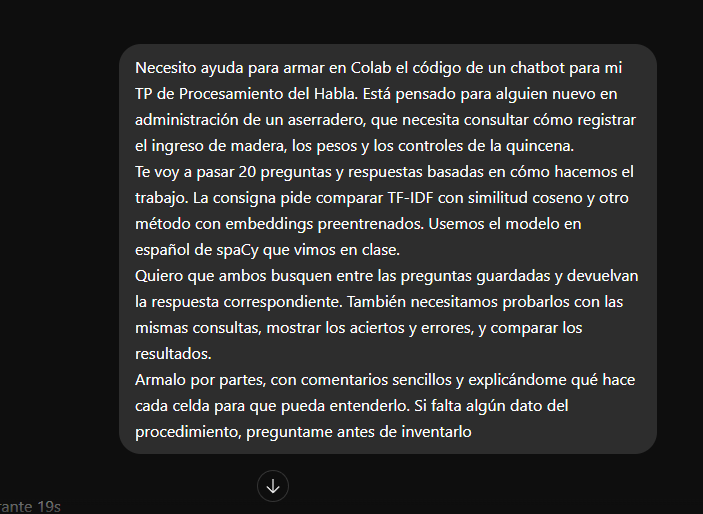
- **Video de presentación y conclusiones:** PENDIENTE DE AGREGAR POR EL ESTUDIANTE

